# 🚦 Sécurité routière à Paris — le danger d'un axe est-il proportionnel à son trafic ?

**Croisement de deux jeux open-data de la Ville de Paris :** les accidents géolocalisés
(`accidentologie0`) et le trafic routier des capteurs permanents
(`comptages-routiers-permanents` + `referentiel-comptages-routiers`).

**Démarche :** cadrage → audit → faisabilité → nettoyage → variables analytiques → EDA →
hypothèse falsifiable → tests statistiques → dataviz → conclusion prudente.


In [11]:
import pandas as pd, requests
BASE = "https://opendata.paris.fr/api/explore/v2.1/catalog/datasets"
acc = pd.DataFrame(requests.get(f"{BASE}/accidentologie0/exports/json", timeout=180).json())
acc.head(5)   # affiche les 5 premières lignes

,annee,idusager,pv,victime_type,categorie,gravite,age,sexe_victime,milieu,adresse,...,resume,coordonnees,nom_arrondissement,arronco,arrondgeo,adresse_1,adresse_2,coordonnes,iris,aondissement
0,2019-01-05,181166120,117,4 Roues,Passager,Blessé léger,36.0,Feminin,En-Agg,PONT DES INVALIDES,...,"Accident Léger non mortel, En agglomération, E...","48.864618, 2.310322",Paris 8e Arrondissement,75108,"{'type': 'Feature', 'geometry': {'coordinates'...",None,None,"{'lon': 2.310322, 'lat': 48.864618}",Paris 8e Arrondissement,75108.0
1,2019-01-05,181166224,125,4 Roues,Conducteur,Blessé léger,34.0,Feminin,En-Agg,RUE JOUFFROY D ABBANS,...,"Accident Léger non mortel, En agglomération, E...","48.88597, 2.30956",Paris 17e Arrondissement,75117,"{'type': 'Feature', 'geometry': {'coordinates'...",None,None,"{'lon': 2.30956, 'lat': 48.88597}",Paris 17e Arrondissement,75117.0
2,2019-01-07,181273873,207,2 Roues Motorisées,Conducteur,Blessé léger,40.0,Masculin,En-Agg,AVENUE MARCEAU,...,"Accident Léger non mortel, En agglomération, E...","48.868534, 2.298904",Paris 16e Arrondissement,75116,"{'type': 'Feature', 'geometry': {'coordinates'...",None,None,"{'lon': 2.298904, 'lat': 48.868534}",Paris 16e Arrondissement,75116.0
3,2019-01-09,181183752,249,2 Roues Motorisées,Conducteur,Blessé léger,24.0,Masculin,En-Agg,QUAI DE LA RAPEE,...,"Accident Léger non mortel, En agglomération, E...","48.845267, 2.368364",Paris 12e Arrondissement,75112,"{'type': 'Feature', 'geometry': {'coordinates'...",None,None,"{'lon': 2.368364, 'lat': 48.845267}",Paris 12e Arrondissement,75112.0
4,2019-01-09,181183702,253,Piéton,Piéton,Blessé léger,67.0,Feminin,En-Agg,RUE DU SENTIER,...,"Accident Léger non mortel, En agglomération, E...","48.867754, 2.345469",Paris 2e Arrondissement,75102,"{'type': 'Feature', 'geometry': {'coordinates'...",None,None,"{'lon': 2.345469, 'lat': 48.867754}",Paris 2e Arrondissement,75102.0


In [12]:
acc["annee"] = pd.to_datetime(acc["annee"])   # texte -> date
acc.sort_values("annee", ascending=False).head(5)

,annee,idusager,pv,victime_type,categorie,gravite,age,sexe_victime,milieu,adresse,...,resume,coordonnees,nom_arrondissement,arronco,arrondgeo,adresse_1,adresse_2,coordonnes,iris,aondissement
30462,2024-12-31,9724580,9241,4 Roues,Conducteur,Blessé léger,70.0,Masculin,En-Agg,BD PERIPHERIQUE INTERIEUR,...,"Accident Léger non mortel, En agglomération, H...",None,None,75114,"{'type': 'Feature', 'geometry': {'coordinates'...",BD PERIPHERIQUE INTERIEUR,None,"{'lon': 2.307761, 'lat': 48.824101}",Paris 14e Arrondissement,75114.0
20262,2024-12-31,9727461,9243,2 Roues Motorisées,Conducteur,Blessé léger,53.0,Masculin,En-Agg,RUE D ALLERAY,...,"Accident Léger non mortel, En agglomération, H...",None,None,75115,"{'type': 'Feature', 'geometry': {'coordinates'...",RUE D ALLERAY,None,"{'lon': 2.305522, 'lat': 48.836504}",Paris 15e Arrondissement,75115.0
12029,2024-12-30,9721314,9231,Piéton,Piéton,Blessé léger,79.0,Masculin,En-Agg,AVENUE DU GENERAL LECLERC,...,"Accident Léger non mortel, En agglomération, E...",None,None,75114,"{'type': 'Feature', 'geometry': {'coordinates'...",Rue Brézin,AVENUE DU GENERAL LECLERC,"{'lon': 2.329377, 'lat': 48.830798}",Paris 14e Arrondissement,75114.0
15932,2024-12-30,9727447,9229,2 Roues Motorisées,Conducteur,Blessé léger,37.0,Masculin,En-Agg,AVENUE DE LA REPUBLIQUE,...,"Accident Léger non mortel, En agglomération, H...",None,None,75111,"{'type': 'Feature', 'geometry': {'coordinates'...",AVENUE DE LA REPUBLIQUE,None,"{'lon': 2.384509, 'lat': 48.863402}",Paris 11e Arrondissement,75111.0
12030,2024-12-30,9724554,9233,4 Roues,Passager,Blessé léger,71.0,Feminin,En-Agg,RUE DE LISBONNE,...,"Accident Léger non mortel, En agglomération, E...",None,None,75108,"{'type': 'Feature', 'geometry': {'coordinates'...",RUE DE LISBONNE,RUE DE TEHERAN,"{'lon': 2.312555, 'lat': 48.877635}",Paris 8e Arrondissement,75108.0


### Piège du champ `annee`
- Nom technique trompeur : `annee` est étiqueté « Date » sur le site et contient une **date au jour** (2019→2024), pas une année.
- Type `str` à l'origine → convertir avec `pd.to_datetime` avant tout tri/filtre temporel.
- L'export n'a **pas d'ordre garanti** : ne jamais conclure d'un `.head()` non trié.

In [13]:
# Certaines colonnes contiennent des dictionnaires (coordonnées) :
# pandas ne sait pas tester l'égalité dessus, donc on les exclut du test de doublons.
hashables = [c for c in acc.columns
             if not acc[c].apply(lambda v: isinstance(v, (dict, list))).any()]

# 1) idusager est-il un identifiant de ligne unique ?
print("Lignes totales   :", len(acc))
print("idusager uniques :", acc["idusager"].nunique())
print("idusager dupliqués :", acc["idusager"].duplicated().sum())

# 2) Vrais doublons = lignes identiques sur TOUTES les colonnes (hashables)
nb_doublons = acc[hashables].duplicated().sum()
print("\nDoublons de lignes complètes :", nb_doublons)

# 3) Rappel : id_accident répété n'est PAS un doublon (plusieurs victimes par accident)
print("id_accident distincts :", acc["id_accident"].nunique(), "(< nb de lignes = normal)")

# 4) Si un jour il y avait des doublons, on les supprimerait ainsi :
# acc = acc.drop_duplicates(subset=hashables).reset_index(drop=True)


Lignes totales   : 33638
idusager uniques : 33638
idusager dupliqués : 0

Doublons de lignes complètes : 0
id_accident distincts : 29425 (< nb de lignes = normal)


### Doublons
- `idusager` : identifiant de ligne, unique (33 638/33 638) → ce n'est PAS la clé accident.
- Vrai doublon = ligne identique sur toutes les colonnes → **0 trouvé**.
- Aucune suppression. La table est propre côté doublons.

In [14]:
acc.head().T

,0,1,2,3,4
annee,2019-01-05 00:00:00,2019-01-05 00:00:00,2019-01-07 00:00:00,2019-01-09 00:00:00,2019-01-09 00:00:00
idusager,181166120,181166224,181273873,181183752,181183702
pv,117,125,207,249,253
victime_type,4 Roues,4 Roues,2 Roues Motorisées,2 Roues Motorisées,Piéton
categorie,Passager,Conducteur,Conducteur,Conducteur,Piéton
gravite,Blessé léger,Blessé léger,Blessé léger,Blessé léger,Blessé léger
age,36.0,34.0,40.0,24.0,67.0
sexe_victime,Feminin,Feminin,Masculin,Masculin,Feminin
milieu,En-Agg,En-Agg,En-Agg,En-Agg,En-Agg
adresse,PONT DES INVALIDES,RUE JOUFFROY D ABBANS,AVENUE MARCEAU,QUAI DE LA RAPEE,RUE DU SENTIER


In [15]:
# Toutes les valeurs distinctes de 'tues', en comptant les vides (NaN)
print(acc["tues"].value_counts(dropna=False))

tues
NaN    33413
1.0      225
Name: count, dtype: int64


a règle de prudence : on ne modifie pas la colonne brute « pour faire propre ». On garde tues tel quel, et on crée une colonne dérivée quand on en a besoin pour un calcul précis

In [16]:
# On NE touche PAS à la colonne brute. On crée une version "compteur" pour les sommes.
acc["est_tue"] = acc["tues"].notna().astype(int)   # 1 si tué, 0 sinon

# Vérification : total de tués, et taux
print("Nombre de victimes tuées :", acc["est_tue"].sum())
print("Part des victimes tuées  :", round(acc["est_tue"].mean()*100, 2), "%")

Nombre de victimes tuées : 225
Part des victimes tuées  : 0.67 %


In [17]:
# Pour chaque ligne : combien des 3 compteurs de gravité sont remplis ?
g = ["blesses_legers", "blesses_hospitalises", "tues"]
nb_remplis = acc[g].notna().sum(axis=1)
print(nb_remplis.value_counts())

# Croisement gravité <-> colonne tues, pour voir la logique
print(acc.groupby("gravite")["tues"].apply(lambda s: s.notna().sum()))

1    33606
2       32
Name: count, dtype: int64
gravite
Blessé hospitalisé      0
Blessé léger            0
Tué                   225
Name: tues, dtype: int64


### Valeurs manquantes & cohérence de la gravité
- `blesses_legers` / `blesses_hospitalises` / `tues` = compteurs **exclusifs** : 1 seule rempli par ligne.
  → un vide n'est PAS une donnée manquante, mais un "non applicable" (vide structurel).
- 33 606 lignes cohérentes (1 case) ; **32 lignes incohérentes** (2 cases) = 0,1 % → notées, non corrigées.
- `tues` est redondant avec `gravite == "Tué"` (225 cas, 0,67 %). On utilisera **`gravite`** comme variable de gravité.
- Règle : ne pas faire de `fillna(0)` aveugle ; créer si besoin une colonne dérivée (ex. `est_tue`).

In [18]:
g = ["blesses_legers", "blesses_hospitalises", "tues"]

# Masque : True pour les lignes où 2 cases (ou plus) sont remplies
masque_double = acc[g].notna().sum(axis=1) >= 2

# Combien y en a-t-il ?
print("Lignes à double comptage :", masque_double.sum())

# Les afficher, avec les colonnes utiles pour comprendre l'incohérence
acc.loc[masque_double, ["id_accident", "gravite"] + g]

Lignes à double comptage : 32


,id_accident,gravite,blesses_legers,blesses_hospitalises,tues
1928,2260051,Tué,1.0,NaN,1.0
5155,3098291,Tué,1.0,NaN,1.0
5179,3178913,Tué,1.0,NaN,1.0
5987,2258598,Tué,1.0,NaN,1.0
6129,2356802,Tué,1.0,NaN,1.0
7918,3175811,Tué,1.0,NaN,1.0
7923,3177010,Tué,1.0,NaN,1.0
9597,2284099,Tué,1.0,NaN,1.0
9624,2289211,Tué,1.0,NaN,1.0
13363,2254949,Tué,1.0,NaN,1.0


### Incohérence des compteurs de gravité (32 lignes)
- Les 32 lignes à double comptage sont TOUTES identiques : gravite="Tué", blesses_legers=1 ET tues=1.
- Cause probable : victime saisie "blessée" puis décédée (règle des 30 jours) → ancien statut non effacé.
- La gravité réelle reste non ambiguë (`gravite="Tué"`).
- Décision : on garde ces lignes, on utilise `gravite` comme variable de gravité, on n'utilise PAS les compteurs `blesses_*`/`tues`.

In [19]:
# 1. Compter les coordonnées manquantes
lat_manq = acc["latitude"].isna().sum()
lon_manq = acc["longitude"].isna().sum()
sans_coord = (acc["latitude"].isna() | acc["longitude"].isna()).sum()

print("Latitude manquante  :", lat_manq)
print("Longitude manquante :", lon_manq)
print("Lignes sans coordonnées utilisables :", sans_coord)
print("Soit", round(sans_coord / len(acc) * 100, 2), "% des accidents")

Latitude manquante  : 0
Longitude manquante : 0
Lignes sans coordonnées utilisables : 0
Soit 0.0 % des accidents


In [23]:
print("Vides AVANT toute conversion :", acc["latitude"].isna().sum())
print("Type Python d'une valeur 'vide' :", type(acc["latitude"].iloc[0]))
print(acc["latitude"].head(10).tolist())

Vides AVANT toute conversion : 0
Type Python d'une valeur 'vide' : <class 'str'>
['48.864618', '48.88597', '48.868534', '48.845267', '48.867754', '48.832538', '48.855064', '48.875239', '48.86054', '48.881']


In [25]:
# Coordonnées : on les prend dans le dict 'coordonnes' (déjà des nombres propres)
acc["latitude"]  = acc["coordonnes"].apply(lambda d: d.get("lat") if isinstance(d, dict) else None)
acc["longitude"] = acc["coordonnes"].apply(lambda d: d.get("lon") if isinstance(d, dict) else None)

print("Manquantes :", (acc["latitude"].isna() | acc["longitude"].isna()).sum())
print("Hors Paris :", (~(acc["latitude"].between(48.80, 48.92) &
                         acc["longitude"].between(2.22, 2.47))).sum())
print(acc[["latitude","longitude"]].describe())

Manquantes : 0
Hors Paris : 2
           latitude     longitude
count  33638.000000  33638.000000
mean      48.860321      2.340925
std        0.021702      0.043821
min       48.815747      2.226179
25%       48.843796      2.307950
50%       48.861913      2.343654
75%       48.876429      2.372641
max       48.901902      2.481252


In [26]:
hors = acc[~(acc["latitude"].between(48.80, 48.92) & acc["longitude"].between(2.22, 2.47))]
print(hors[["id_accident", "latitude", "longitude", "adresse", "nom_arrondissement"]])

      id_accident   latitude  longitude adresse   nom_arrondissement
2914     66538894  48.829180   2.481252      A4  Champigny-sur-Marne
15229    63435065  48.828386   2.474913      A4    Joinville-le-Pont


In [27]:
avant = len(acc)
acc = acc[acc["latitude"].between(48.80, 48.92) & acc["longitude"].between(2.22, 2.47)].copy()
print(f"Accidents conservés : {len(acc)} (retiré {avant - len(acc)})")

Accidents conservés : 33636 (retiré 2)


### Coordonnées hors périmètre
- 2 accidents localisés sur l'A4 (Champigny, Joinville) → Val-de-Marne, hors Paris.
- Valides techniquement mais hors sujet → exclus.
- Règle : filtrer sur les bornes géographiques de Paris (lat 48.80–48.92, lon 2.22–2.47).

In [28]:
# La colonne 'annee' est une date (déjà convertie en cellule 2). On la nettoie au cas où.
acc["date"] = pd.to_datetime(acc["annee"], errors="coerce")

print("Dates manquantes :", acc["date"].isna().sum())
print("Période          :", acc["date"].min(), "->", acc["date"].max())

# Répartition par année : cohérence (pas d'année hors 2019-2024 ?)
print("\nAccidents par année :")
print(acc["date"].dt.year.value_counts().sort_index())

Dates manquantes : 0
Période          : 2019-01-01 00:00:00 -> 2024-12-31 00:00:00

Accidents par année :
date
2019    6364
2020    5349
2021    5846
2022    5801
2023    5451
2024    4825
Name: count, dtype: int64


### Dates (`annee`)
- 0 manquante, période 2019-01-01 → 2024-12-31 (6 années complètes), aucune aberration.
- Victimes/an : 6364 (2019) → 4825 (2024), soit −24 %. Creux Covid en 2020.
- Tendance notée sans interprétation causale (sécurité réelle vs évolution du recensement).

In [29]:
for col in ["gravite", "victime_type", "categorie", "sexe_victime"]:
    print(f"===== {col} =====")
    print(acc[col].value_counts(dropna=False))
    print()

===== gravite =====
gravite
Blessé léger          31214
Blessé hospitalisé     2197
Tué                     225
Name: count, dtype: int64

===== victime_type =====
victime_type
2 Roues Motorisées    13076
Piéton                 6870
Vélo                   6026
4 Roues                5836
EDP-m                  1827
Autres                    1
Name: count, dtype: int64

===== categorie =====
categorie
Conducteur    23268
Piéton         6721
Passager       3647
Name: count, dtype: int64

===== sexe_victime =====
sexe_victime
Masculin    22853
Feminin     10783
Name: count, dtype: int64



### Variables catégorielles
- gravite : 3 modalités, 0 vide (93% légers / 6,5% hospitalisés / 0,67% tués).
- victime_type : 5 catégories ; usagers vulnérables (2RM, piétons, vélos, EDP) >> voitures.
- categorie : Conducteur / Piéton / Passager, propre.
- sexe_victime : 2 modalités, 0 vide, ~2/3 hommes.
- Aucun doublon de libellé ni faute de casse. Qualité catégorielle élevée.

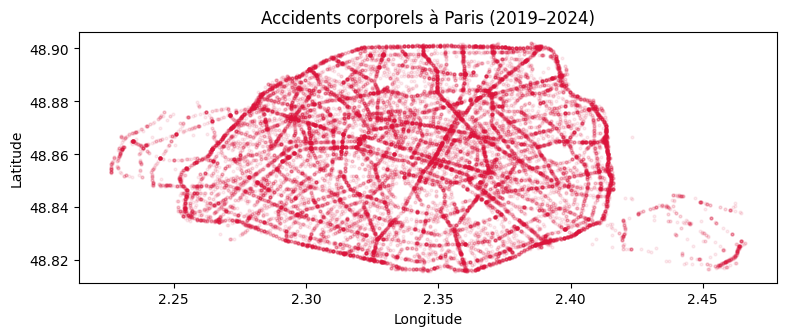

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 8))
plt.scatter(acc["longitude"], acc["latitude"], s=4, alpha=0.08, color="crimson")
plt.gca().set_aspect("equal")          # respecte les proportions géographiques
plt.title("Accidents corporels à Paris (2019–2024)")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.show()

### Carte des accidents (2019–2024)
- Les accidents redessinent le réseau routier parisien (périphérique + grands axes très visibles).
- Concentration nette sur le périph et les boulevards ; bois de Boulogne/Vincennes en excroissances.
- ⚠️ Lecture en ABSOLU : forte densité ≠ forte dangerosité tant qu'on ne normalise pas par le trafic.

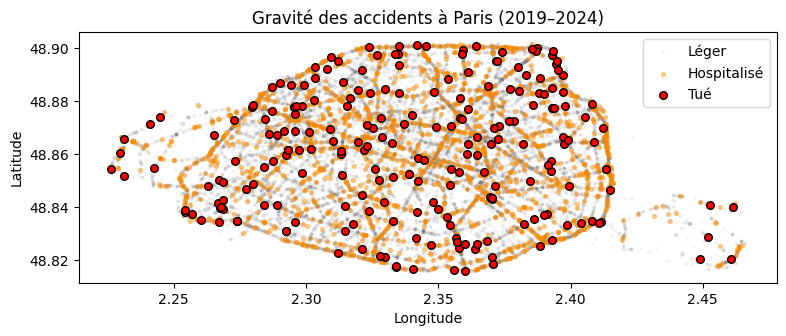

In [31]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 8))

# Fond : blessés légers, très pâles
leg = acc[acc["gravite"] == "Blessé léger"]
ax.scatter(leg["longitude"], leg["latitude"], s=3, alpha=0.05, color="grey", label="Léger")

# Par-dessus : hospitalisés
hosp = acc[acc["gravite"] == "Blessé hospitalisé"]
ax.scatter(hosp["longitude"], hosp["latitude"], s=8, alpha=0.4, color="darkorange", label="Hospitalisé")

# Au sommet : tués (les plus rares, les plus visibles)
tue = acc[acc["gravite"] == "Tué"]
ax.scatter(tue["longitude"], tue["latitude"], s=30, color="red", edgecolor="black", label="Tué")

ax.set_aspect("equal")
ax.set_title("Gravité des accidents à Paris (2019–2024)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.legend()
plt.show()

### Carte par gravité
- Tués (225) et hospitalisés répartis sur tout le réseau, sans concentration visible à l'œil.
- La distribution des graves suit globalement celle de l'ensemble des accidents.
- ⚠️ 225 points sont trop peu pour juger visuellement → toute conclusion sur la localisation
  de la gravité devra passer par un TAUX calculé (graves / total) par zone, pas par l'œil.

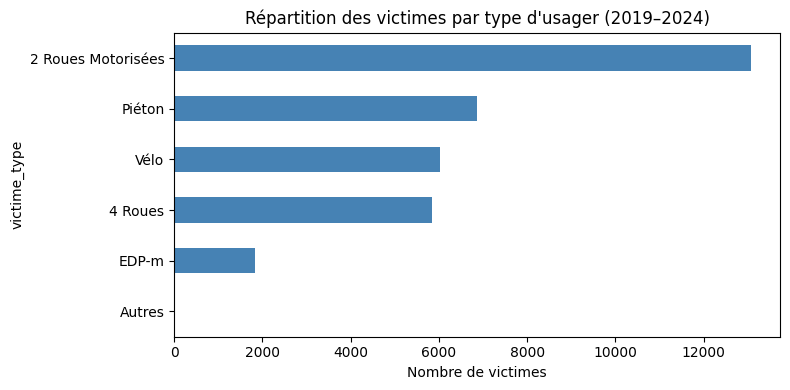

victime_type
2 Roues Motorisées    38.9
Piéton                20.4
Vélo                  17.9
4 Roues               17.4
EDP-m                  5.4
Autres                 0.0
Name: count, dtype: float64


In [32]:
import matplotlib.pyplot as plt

vc = acc["victime_type"].value_counts()

plt.figure(figsize=(8, 4))
vc.sort_values().plot(kind="barh", color="steelblue")
plt.title("Répartition des victimes par type d'usager (2019–2024)")
plt.xlabel("Nombre de victimes")
plt.tight_layout()
plt.show()

# Part en pourcentage
print((vc / vc.sum() * 100).round(1))

### Répartition par type d'usager
- Usagers vulnérables (2RM 38,9% + piétons 20,4% + vélos 17,9% + EDP 5,4%) = 82,6% des victimes.
- Occupants de voiture : 17,4%. → +4 victimes sur 5 ne sont pas en voiture.
- ⚠️ Ce sont des parts de victimes, PAS des taux de risque (manque l'exposition par mode).

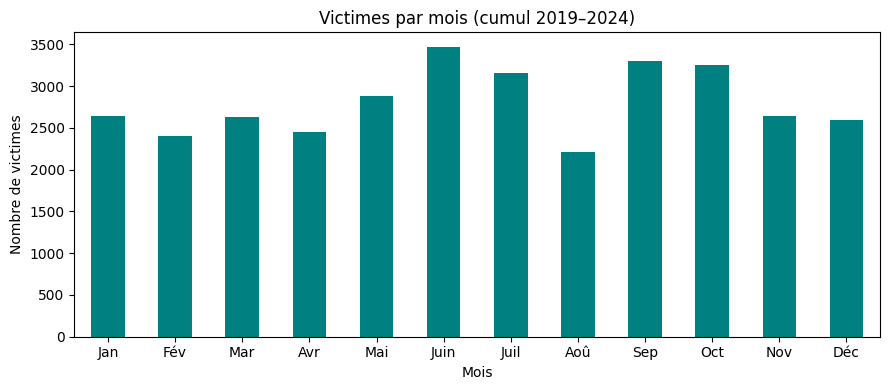

In [33]:
import matplotlib.pyplot as plt

par_mois = acc["date"].dt.month.value_counts().sort_index()

plt.figure(figsize=(9, 4))
par_mois.plot(kind="bar", color="teal")
plt.title("Victimes par mois (cumul 2019–2024)")
plt.xlabel("Mois"); plt.ylabel("Nombre de victimes")
plt.xticks(range(12), ["Jan","Fév","Mar","Avr","Mai","Juin","Juil","Aoû","Sep","Oct","Nov","Déc"], rotation=0)
plt.tight_layout()
plt.show()

### Saisonnalité
- Pic en juin (~3450) et à la rentrée (sept-oct) ; creux marqué en août (~2200).
- Cohérent : beaux jours → plus de vélos/2-roues ; août → Paris se vide.
- ⚠️ Volume absolu, pas un taux de risque (manque l'exposition mensuelle).

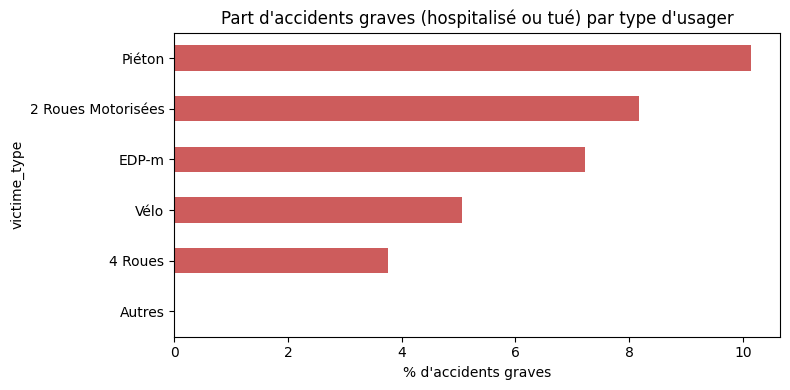

victime_type
Autres                 0.0
4 Roues                3.8
Vélo                   5.1
EDP-m                  7.2
2 Roues Motorisées     8.2
Piéton                10.1
Name: grave, dtype: float64


In [34]:
# Taux d'accidents graves (hospitalisé + tué) par type d'usager
acc["grave"] = acc["gravite"].isin(["Blessé hospitalisé", "Tué"])
taux = acc.groupby("victime_type")["grave"].mean().sort_values() * 100

plt.figure(figsize=(8, 4))
taux.plot(kind="barh", color="indianred")
plt.title("Part d'accidents graves (hospitalisé ou tué) par type d'usager")
plt.xlabel("% d'accidents graves")
plt.tight_layout()
plt.show()

print(taux.round(1))

### Gravité par type d'usager (taux de risque)
- Part d'accidents graves : Piéton 10,1% > 2RM 8,2% > EDP 7,2% > Vélo 5,1% > Voiture 3,8%.
- Gradient net : moins l'usager est protégé, plus l'accident est grave.
- Ratio interne à chaque mode → l'exposition est neutralisée : comparaison légitime.
- Réserve : effectifs plus faibles pour EDP/Autres → taux moins robustes.

In [36]:
import requests, pandas as pd
BASE = "https://opendata.paris.fr/api/explore/v2.1/catalog/datasets"

# Métadonnées : combien de lignes au total ?
meta = requests.get(f"{BASE}/comptages-routiers-permanents", timeout=60).json()
print("Nombre total de lignes :", meta["metas"]["default"]["records_count"])

# Un petit échantillon (5 lignes) pour voir les colonnes — SANS tout télécharger
ech = pd.DataFrame(requests.get(
    f"{BASE}/comptages-routiers-permanents/records",
    params={"limit": 5}, timeout=60).json()["results"])
print("\nColonnes :", ech.columns.tolist())
ech

Nombre total de lignes : 27704775

Colonnes : ['iu_ac', 'libelle', 't_1h', 'q', 'k', 'etat_trafic', 'iu_nd_amont', 'libelle_nd_amont', 'iu_nd_aval', 'libelle_nd_aval', 'etat_barre', 'date_debut', 'date_fin', 'geo_point_2d', 'geo_shape']


,iu_ac,libelle,t_1h,q,k,etat_trafic,iu_nd_amont,libelle_nd_amont,iu_nd_aval,libelle_nd_aval,etat_barre,date_debut,date_fin,geo_point_2d,geo_shape
0,5564,Vaugirard,2025-05-09T09:00:00+00:00,429.0,NaN,Inconnu,2918,Vaugirard-Beuchet,2919,Vaugirard-Cambronne,Ouvert,1996-12-12,2023-01-01,"{'lon': 2.303221025755864, 'lat': 48.840145935...","{'type': 'Feature', 'geometry': {'coordinates'..."
1,5565,Vaugirard,2025-05-09T12:00:00+00:00,543.0,8.08778,Fluide,2919,Vaugirard-Cambronne,2920,Vaugirard-Volontaires,Ouvert,1996-12-12,2023-01-01,"{'lon': 2.3060707136945666, 'lat': 48.84094492...","{'type': 'Feature', 'geometry': {'coordinates'..."
2,5566,Vaugirard,2025-05-09T11:00:00+00:00,409.0,6.50389,Fluide,2920,Vaugirard-Volontaires,2921,Vaugirard-Stael,Ouvert,1996-12-12,2023-01-01,"{'lon': 2.3094673071309275, 'lat': 48.84195756...","{'type': 'Feature', 'geometry': {'coordinates'..."
3,5566,Vaugirard,2025-05-09T09:00:00+00:00,382.0,9.84056,Fluide,2920,Vaugirard-Volontaires,2921,Vaugirard-Stael,Ouvert,1996-12-12,2023-01-01,"{'lon': 2.3094673071309275, 'lat': 48.84195756...","{'type': 'Feature', 'geometry': {'coordinates'..."
4,5761,Bd_Pasteur,2025-05-09T12:00:00+00:00,NaN,NaN,Inconnu,3014,Bd_Pasteur-Guillout,2922,Vaugirard-Bd_Pasteur,Invalide,1997-03-13,2023-01-01,"{'lon': 2.3130683036444166, 'lat': 48.84263520...","{'type': 'Feature', 'geometry': {'coordinates'..."


### Trafic : structure & pièges repérés
- 27,7 M de lignes → chargement complet impossible : on agrégera côté serveur (débit moyen/capteur).
- Colonnes clés : `iu_ac` (capteur, clé de jointure), `q` (débit véh/h = exposition), `t_1h` (horodatage).
- `t_1h` est en UTC (+00:00) ≠ heure locale Paris. Piège noté, mais SANS impact ici car on moyenne
  le débit sur toutes les heures (la dimension horaire a été abandonnée en phase de faisabilité).
- `q` et `k` contiennent des NaN → nettoyage à prévoir.

### Valeurs manquantes du trafic (`q`)
- q = NaN signifie "capteur non mesuré" (etat "Inconnu"/"Invalide"), PAS "0 véhicule".
- Ne pas remplacer par 0 (sous-estimerait le débit). La moyenne ignore nativement les NaN.
- Vrai filtre de fiabilité : écarter les capteurs avec trop peu d'observations valides (count >= 2000).

In [37]:
import requests, pandas as pd
BASE = "https://opendata.paris.fr/api/explore/v2.1/catalog/datasets"

rows, off = [], 0
while True:
    r = requests.get(
        f"{BASE}/comptages-routiers-permanents/records",
        params={
            "select": "iu_ac, avg(q) as q_moy, count(*) as n_obs",  # le serveur calcule la moyenne
            "group_by": "iu_ac",     # un résultat par capteur
            "limit": 100,            # l'API plafonne à 100 lignes par appel
            "offset": off            # on avance de 100 en 100
        }, timeout=120)
    res = r.json().get("results", [])
    if not res:
        break
    rows += res
    off += 100
    if off >= 10000:                 # garde-fou (limite d'offset de l'API)
        break

traf = pd.DataFrame(rows)
traf["iu_ac"] = traf["iu_ac"].astype(str)
print("Capteurs récupérés :", len(traf))
print(traf.head())
print("\nDébit moyen (q_moy) — stats :")
print(traf["q_moy"].describe())

Capteurs récupérés : 2989
  iu_ac        q_moy  n_obs
0     *          NaN      1
1     1  1348.972583   9302
2    10  1112.773095   9302
3   100   300.114807   9302
4  1001          NaN   9294

Débit moyen (q_moy) — stats :
count    1977.000000
mean      566.734677
std       858.326547
min         0.000000
25%       186.719555
50%       304.075719
75%       516.548224
max      5105.246965
Name: q_moy, dtype: float64


In [38]:
avant = len(traf)
traf = traf[traf["iu_ac"] != "*"]              # ligne parasite
traf = traf.dropna(subset=["q_moy"])           # capteurs sans débit valide
traf = traf[traf["n_obs"] >= 2000]             # fiabilité : assez d'heures mesurées
print(f"Capteurs conservés : {len(traf)} (retiré {avant - len(traf)})")
print(traf["q_moy"].describe())

Capteurs conservés : 1975 (retiré 1014)
count    1975.000000
mean      566.953577
std       858.728430
min         0.000000
25%       186.719555
50%       304.075719
75%       516.548224
max      5105.246965
Name: q_moy, dtype: float64


### Trafic agrégé par capteur (parade aux 27 M de lignes)
- Agrégation côté serveur (avg(q) group by iu_ac) → 2989 capteurs, puis nettoyage.
- Retirés : iu_ac="*" (parasite), q_moy NaN (~1000 capteurs sans débit valide), n_obs < 2000 (fiabilité).
- Conservés : 1975 capteurs. Débit médian 304 véh/h, max 5105 → forte hiérarchie des axes.
- Réserve : quelques capteurs à q_moy=0 (axe désert ou capteur défaillant ?) à surveiller.

In [39]:
ref = pd.DataFrame(requests.get(f"{BASE}/referentiel-comptages-routiers/exports/json", timeout=120).json())
print("Dimensions :", ref.shape)
print("Colonnes   :", ref.columns.tolist())
ref.head(3)

Dimensions : (3739, 10)
Colonnes   : ['iu_ac', 'date_debut', 'date_fin', 'libelle', 'iu_nd_aval', 'libelle_nd_aval', 'iu_nd_amont', 'libelle_nd_amont', 'geo_point_2d', 'geo_shape']


,iu_ac,date_debut,date_fin,libelle,iu_nd_aval,libelle_nd_aval,iu_nd_amont,libelle_nd_amont,geo_point_2d,geo_shape
0,4234,1996-10-10T02:00:00+00:00,2023-01-01T01:00:00+00:00,Bd_Berthier,2276,Pl_Paul_Leautaud,2254,Bd_Berthier-Roll,"{'lon': 2.298712467436026, 'lat': 48.887700029...","{'type': 'Feature', 'geometry': {'coordinates'..."
1,5223,1996-10-25T02:00:00+00:00,2023-01-01T01:00:00+00:00,Bd_Gouvion_St_Cyr,2752,Place_Jean_Renard,2753,Av_Pte_Villiers-Gouvion_St_Cyr,"{'lon': 2.288427098532499, 'lat': 48.883578018...","{'type': 'Feature', 'geometry': {'coordinates'..."
2,4236,1996-10-10T02:00:00+00:00,2023-01-01T01:00:00+00:00,Bd_Berthier,2254,Bd_Berthier-Roll,2276,Pl_Paul_Leautaud,"{'lon': 2.2988620207981394, 'lat': 48.88759791...","{'type': 'Feature', 'geometry': {'coordinates'..."


In [40]:
# Extraire lat/lon du dictionnaire
ref["lat"] = ref["geo_point_2d"].apply(lambda d: d.get("lat") if isinstance(d, dict) else None)
ref["lon"] = ref["geo_point_2d"].apply(lambda d: d.get("lon") if isinstance(d, dict) else None)
ref["iu_ac"] = ref["iu_ac"].astype(str)

# Vérifs avant jointure
print("Lignes              :", len(ref))
print("iu_ac uniques       :", ref["iu_ac"].nunique())
print("iu_ac dupliqués     :", ref["iu_ac"].duplicated().sum())
print("Coordonnées manquantes :", ref["lat"].isna().sum())

Lignes              : 3739
iu_ac uniques       : 3348
iu_ac dupliqués     : 391
Coordonnées manquantes : 0


In [41]:
# Un iu_ac qui apparaît plusieurs fois
exemple = ref["iu_ac"].value_counts()
print(exemple.head(5))   # les iu_ac les plus dupliqués

# On en inspecte un en détail
dup_id = exemple.index[0]
print(f"\n--- Détail du capteur {dup_id} ---")
print(ref[ref["iu_ac"] == dup_id][["iu_ac", "libelle", "date_debut", "date_fin", "lat", "lon"]])

iu_ac
5113    6
5469    6
5909    4
5908    4
5891    4
Name: count, dtype: int64

--- Détail du capteur 5113 ---
     iu_ac          libelle                 date_debut  \
1540  5113  Pl_de_la_Nation  1996-10-21T02:00:00+00:00   
1634  5113  Pl_de_la_Nation  2005-01-01T01:00:00+00:00   
2020  5113  Pl_de_la_Nation  2005-01-01T01:00:00+00:00   
2021  5113  Pl_de_la_Nation  2005-01-01T01:00:00+00:00   
2215  5113  Pl_de_la_Nation  2005-01-01T01:00:00+00:00   
2379  5113  Pl_de_la_Nation  2005-01-01T01:00:00+00:00   

                       date_fin        lat       lon  
1540  2023-01-01T01:00:00+00:00  48.847872  2.395454  
1634  2019-06-01T02:00:00+00:00  48.848391  2.394904  
2020  2019-06-01T02:00:00+00:00  48.848664  2.395037  
2021  2019-06-01T02:00:00+00:00  48.848896  2.395363  
2215  2019-06-01T02:00:00+00:00  48.848991  2.395814  
2379  2019-06-01T02:00:00+00:00  48.848114  2.395020  


In [42]:
# Une position représentative (centre de gravité) par capteur
ref_uniq = (ref.groupby("iu_ac")
              .agg(libelle=("libelle", "first"),
                   lat=("lat", "mean"),
                   lon=("lon", "mean"))
              .reset_index())

print("Capteurs uniques :", len(ref_uniq))
print("iu_ac dupliqués  :", ref_uniq["iu_ac"].duplicated().sum())  # doit être 0
ref_uniq.head(3)

Capteurs uniques : 3348
iu_ac dupliqués  : 0


,iu_ac,libelle,lat,lon
0,1,Quai_du_Louvre,48.859838,2.334242
1,10,Quai_de_Gesvres,48.856269,2.350029
2,100,Monge,48.849398,2.349550


In [43]:
# Dispersion géographique de chaque capteur (avant regroupement)
disp = ref.groupby("iu_ac").agg(
    lat_min=("lat", "min"), lat_max=("lat", "max"),
    lon_min=("lon", "min"), lon_max=("lon", "max"))

# Écart max en degrés -> approximé en mètres (1° lat ≈ 111 km)
disp["etendue_m"] = ((disp["lat_max"] - disp["lat_min"]) * 111000).round(0)
print("Étendue géographique des capteurs (mètres) :")
print(disp["etendue_m"].describe())
print("\nCapteurs les plus dispersés :")
print(disp["etendue_m"].sort_values(ascending=False).head())

Étendue géographique des capteurs (mètres) :
count    3348.000000
mean        6.978196
std        28.358652
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       408.000000
Name: etendue_m, dtype: float64

Capteurs les plus dispersés :
iu_ac
4957    408.0
4140    329.0
1806    324.0
6597    317.0
1554    316.0
Name: etendue_m, dtype: float64


### Référentiel des capteurs : dédoublonnage
- 3739 lignes → 3348 capteurs uniques (391 iu_ac dupliqués).
- Cause : grands carrefours = plusieurs points de mesure sous un même iu_ac (coordonnées proches).
- Position retenue = moyenne (centre de gravité) des points de chaque capteur.
- Vérif de dispersion : 75% à 0 m, moyenne 7 m, max 408 m. Moyenne validée.
- Limite notée : ~5 capteurs étendus à 300-400 m → imprécision marginale assumée.

In [44]:
# Capteurs présents dans le trafic mais ABSENTS du référentiel (donc sans position)
traf_ids = set(traf["iu_ac"])
ref_ids  = set(ref_uniq["iu_ac"])

sans_position = traf_ids - ref_ids   # dans traf, pas dans ref
print("Capteurs avec débit (traf)        :", len(traf_ids))
print("Capteurs avec position (ref_uniq) :", len(ref_ids))
print("Capteurs de traf SANS position    :", len(sans_position))
print("Capteurs exploitables (débit + position) :", len(traf_ids & ref_ids))

Capteurs avec débit (traf)        : 1975
Capteurs avec position (ref_uniq) : 3348
Capteurs de traf SANS position    : 17
Capteurs exploitables (débit + position) : 1958


In [45]:
cap = traf.merge(ref_uniq, on="iu_ac", how="inner")
print("Capteurs après fusion débit + position :", len(cap))
print(cap[["iu_ac", "libelle", "q_moy", "lat", "lon"]].head())

Capteurs après fusion débit + position : 1958
  iu_ac          libelle        q_moy        lat       lon
0     1   Quai_du_Louvre  1348.972583  48.859838  2.334242
1    10  Quai_de_Gesvres  1112.773095  48.856269  2.350029
2   100            Monge   300.114807  48.849398  2.349550
3   101         Lagrange   122.157718  48.851119  2.348306
4  1010  Pl_25_Aout_1944   347.128747  48.822588  2.325210


In [46]:
zeros = cap[cap["q_moy"] == 0]
print("Capteurs à débit moyen nul :", len(zeros))
print(zeros[["iu_ac", "libelle", "q_moy"]])

Capteurs à débit moyen nul : 2
     iu_ac            libelle  q_moy
1290  5483   AI_A3_bretelle_2    0.0
1547  6088  AE_A6A_bretelle_8    0.0


In [47]:
avant = len(cap)
cap = cap[cap["q_moy"] > 0].copy()
print(f"Capteurs conservés : {len(cap)} (retiré {avant - len(cap)})")

Capteurs conservés : 1956 (retiré 2)


### Capteurs à débit nul
- 2 capteurs à q_moy = 0 : bretelles d'autoroute (A3, A6a) → capteurs défaillants (une bretelle n'est jamais déserte).
- Risque = accidents / débit → q_moy=0 provoquerait une division par zéro (inf).
- Décision : retirés (invalides + dangereux pour le calcul). Reste 1956 capteurs.

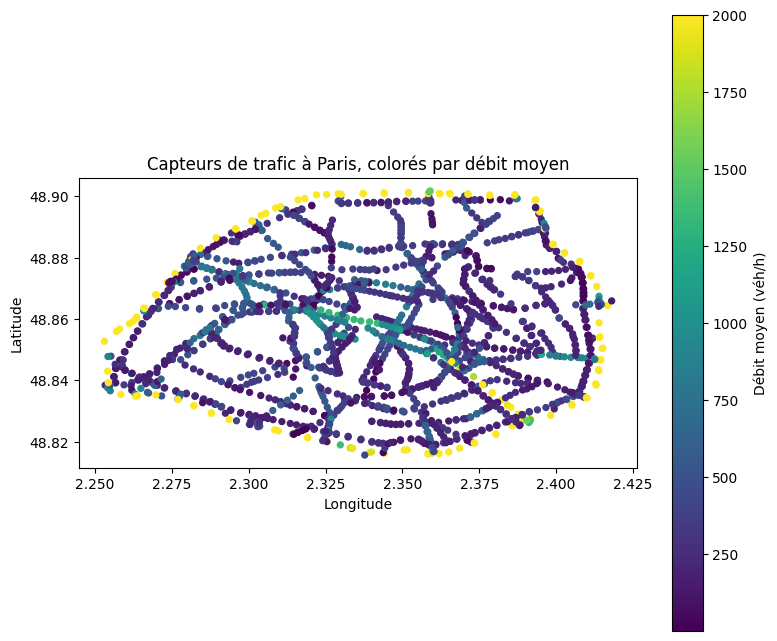

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 8))
sc = plt.scatter(cap["lon"], cap["lat"],
                 c=cap["q_moy"], cmap="viridis",
                 s=18, vmax=2000)            # vmax : on plafonne pour mieux voir les nuances
plt.colorbar(sc, label="Débit moyen (véh/h)")
plt.gca().set_aspect("equal")
plt.title("Capteurs de trafic à Paris, colorés par débit moyen")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.show()

### Carte des capteurs (débit moyen)
- Couverture homogène de tout Paris → bonne représentativité spatiale.
- Le périphérique ressort nettement en fort débit → q_moy capte bien la hiérarchie des voies (exposition validée).
- Choix matplotlib (et non Folium/GeoPandas) : exploration rapide ; Folium réservé à la dataviz finale interactive.

In [49]:
import numpy as np
from scipy.spatial import cKDTree

# 1. Convertir lat/lon en mètres (projection approchée, valable à l'échelle de Paris)
def to_xy(lat, lon):
    return np.c_[(lon - 2.35) * 73000.0, (lat - 48.86) * 111000.0]

# 2. Construire l'arbre sur les capteurs, puis chercher le plus proche pour chaque accident
tree = cKDTree(to_xy(cap["lat"].values, cap["lon"].values))
dist, idx = tree.query(to_xy(acc["latitude"].values, acc["longitude"].values), k=1)

# 3. Rattacher : à chaque accident, le capteur trouvé + la distance + son débit
acc["cap_iu"]     = cap["iu_ac"].values[idx]
acc["cap_dist_m"] = dist
acc["cap_q_moy"]  = cap["q_moy"].values[idx]

print("Distance accident → capteur le plus proche (mètres) :")
print(acc["cap_dist_m"].describe())

Distance accident → capteur le plus proche (mètres) :
count    33636.000000
mean       170.059601
std        399.503473
min          0.356734
25%         45.558515
50%         79.746116
75%        156.068459
max       4182.877569
Name: cap_dist_m, dtype: float64


In [50]:
RAYON = 150  # mètres
near = acc[acc["cap_dist_m"] <= RAYON].copy()
print(f"Accidents rattachés (≤ {RAYON} m) : {len(near)} sur {len(acc)} "
      f"({100*len(near)/len(acc):.0f}%)")
print(f"Accidents écartés (trop loin)    : {len(acc) - len(near)}")

Accidents rattachés (≤ 150 m) : 24840 sur 33636 (74%)
Accidents écartés (trop loin)    : 8796


### Croisement spatial accident → capteur (KD-Tree)
- Plus proche voisin via KD-Tree ; distances : médiane 80 m, 75% < 156 m, max 4183 m.
- Seuil de rattachement : 150 m (compromis, juste au-dessus du 3e quartile).
- 24 840 accidents rattachés (74%) ; 8 796 écartés (26%).
- BIAIS DÉCLARÉ : les accidents écartés sont ceux des petites rues loin des capteurs.
  → L'étude porte sur le RÉSEAU STRUCTURANT (grands axes), pas sur toutes les rues de Paris.
  → Aucune conclusion possible sur la sécurité des rues résidentielles non instrumentées.

In [51]:
# 1. Nombre d'ACCIDENTS DISTINCTS par capteur (rappel du grain : id_accident, pas les lignes !)
acc_par_cap = near.groupby("cap_iu")["id_accident"].nunique().reset_index()
acc_par_cap.columns = ["iu_ac", "n_acc"]

# 2. On rattache ce comptage à la table des capteurs
cap = cap.merge(acc_par_cap, on="iu_ac", how="left")
cap["n_acc"] = cap["n_acc"].fillna(0).astype(int)   # capteur sans accident rattaché = 0

# 3. LE calcul clé : risque = accidents pour 1000 véhicules/h
cap["risque_1000veh"] = cap["n_acc"] / (cap["q_moy"] / 1000)

print(cap[["iu_ac", "libelle", "q_moy", "n_acc", "risque_1000veh"]].head(10))
print("\nRisque pour 1000 véh — stats :")
print(cap["risque_1000veh"].describe())

  iu_ac             libelle        q_moy  n_acc  risque_1000veh
0     1      Quai_du_Louvre  1348.972583     34       25.204367
1    10     Quai_de_Gesvres  1112.773095      5        4.493279
2   100               Monge   300.114807      4       13.328233
3   101            Lagrange   122.157718     10       81.861385
4  1010     Pl_25_Aout_1944   347.128747      4       11.523102
5  1011     Pl_25_Aout_1944   520.004435     17       32.692029
6  1017       Av_Pte_d'Ivry    77.406399     13      167.944771
7  1018       Av_Pte_d'Ivry   214.512125      0        0.000000
8  1027  Pont_du_Garigliano   819.200000      3        3.662109
9  1028  Pont_du_Garigliano   407.489403      2        4.908103

Risque pour 1000 véh — stats :
count     1956.000000
mean        72.466471
std        692.416523
min          0.000000
25%          9.833966
50%         24.380405
75%         52.378089
max      23029.411765
Name: risque_1000veh, dtype: float64


In [52]:
# Les capteurs au risque le plus délirant
print(cap.sort_values("risque_1000veh", ascending=False)
        [["iu_ac", "libelle", "q_moy", "n_acc", "risque_1000veh"]].head(10))

# Combien de capteurs ont un débit très faible (< 50 véh/h) ?
print("\nCapteurs à débit < 50 véh/h :", (cap["q_moy"] < 50).sum())

     iu_ac                    libelle      q_moy  n_acc  risque_1000veh
1850   750  Av_de_la_Pte_de_Chatillon   1.172414     27    23029.411765
1939   924           Pte_de_Chatillon   1.172414     20    17058.823529
896   4821               Av_Daumesnil   0.500000      5    10000.000000
1848   748  Av_de_la_Pte_de_Chatillon   1.172414      2     1705.882353
528    403            Bd_Beaumarchais  17.576584     27     1536.134692
521    401            Bd_Beaumarchais  17.576584     27     1536.134692
977   4963                Av_Secretan  31.680031     46     1452.018781
126   1378            Bd_Beaumarchais  17.576584     24     1365.453059
127   1380            Bd_Beaumarchais  17.576584     20     1137.877549
1167  5286            Bd_Amiral_Bruix  10.488876     11     1048.730150

Capteurs à débit < 50 véh/h : 49


In [53]:
SEUIL_Q = 50  # véh/h minimum pour un débit crédible
avant = len(cap)
cap = cap[cap["q_moy"] >= SEUIL_Q].copy()
# on recalcule le risque proprement
cap["risque_1000veh"] = cap["n_acc"] / (cap["q_moy"] / 1000)

print(f"Capteurs conservés : {len(cap)} (retiré {avant - len(cap)})")
print(cap["risque_1000veh"].describe())

Capteurs conservés : 1907 (retiré 49)
count    1907.000000
mean       38.273613
std        49.297977
min         0.000000
25%         9.589060
50%        23.077673
75%        49.640509
max       713.879024
Name: risque_1000veh, dtype: float64


### Calcul du risque & fiabilisation du dénominateur
- Risque = accidents distincts / (q_moy / 1000) = accidents pour 1000 véh/h.
- Premier calcul : max=23029 (absurde) car capteurs à débit minuscule (1 à 17 véh/h) → ratio explose.
- 49 capteurs à q_moy < 50 véh/h = mesures de trafic non crédibles → retirés.
- Justification : filtre sur la QUALITÉ de la mesure (débit implausible), pas sur le résultat.
- Après : 1907 capteurs, max=714, écart-type 692→49. Indicateur fiable.

In [54]:
# 4 tiers de trafic, du plus faible (T1) au plus fort (T4) — quartiles égaux
cap["tier"] = pd.qcut(cap["q_moy"], 4, labels=["T1 faible", "T2 moyen", "T3 élevé", "T4 fort"])

# Synthèse par tier
synth = cap.groupby("tier", observed=True).agg(
    nb_capteurs   = ("iu_ac", "count"),
    debit_moyen   = ("q_moy", "mean"),
    acc_moyen     = ("n_acc", "mean"),
    risque_median = ("risque_1000veh", "median")
).round(2)

print(synth)

           nb_capteurs  debit_moyen  acc_moyen  risque_median
tier                                                         
T1 faible          480       138.77       8.38          48.18
T2 moyen           474       243.51       9.88          30.44
T3 élevé           476       398.42      11.33          22.89
T4 fort            477      1554.64      15.16           9.79


### RÉSULTAT CENTRAL — risque par tier de trafic
- Accidents EN ABSOLU : croissent avec le trafic (8,4 → 15,2 par capteur).
- Risque PAR VÉHICULE : s'effondre (48 → 10 pour 1000 véh), gradient monotone.
- Les axes les plus circulés (T4, périph) sont ~5x plus sûrs par véhicule que les petites voies (T1).
- Hypothèse confirmée : le danger d'un axe n'est PAS proportionnel à son trafic.
- À confirmer par un test statistique (médianes ≠ preuve).

In [55]:
from scipy.stats import kruskal, spearmanr

# Données propres (on enlève les risques infinis/NaN éventuels)
m = cap.replace([np.inf, -np.inf], np.nan).dropna(subset=["q_moy", "risque_1000veh"])

# TEST 1 — Kruskal-Wallis : les 4 tiers ont-ils des risques différents ?
groupes = [g["risque_1000veh"].values for _, g in m.groupby("tier", observed=True)]
H, p_kw = kruskal(*groupes)
print(f"Kruskal-Wallis : H = {H:.1f}, p = {p_kw:.2e}")

# TEST 2 — Spearman : corrélation (de rang) entre débit et risque
rho, p_sp = spearmanr(m["q_moy"], m["risque_1000veh"])
print(f"Spearman       : rho = {rho:.3f}, p = {p_sp:.2e}")

Kruskal-Wallis : H = 360.4, p = 8.35e-78
Spearman       : rho = -0.460, p = 3.01e-100


### Tests statistiques
- Kruskal-Wallis : H=360, p=8e-78 → les 4 tiers ont des risques significativement différents.
- Spearman : rho=-0,46 (p=3e-100) → le risque/véhicule décroît avec le débit, de façon très significative.
- Corrélation MODÉRÉE : le trafic explique une partie du risque, pas tout.
- Corrélation ≠ causalité : les axes à fort débit (périph) sont sûrs car séparés/sans carrefours, pas "grâce au trafic".

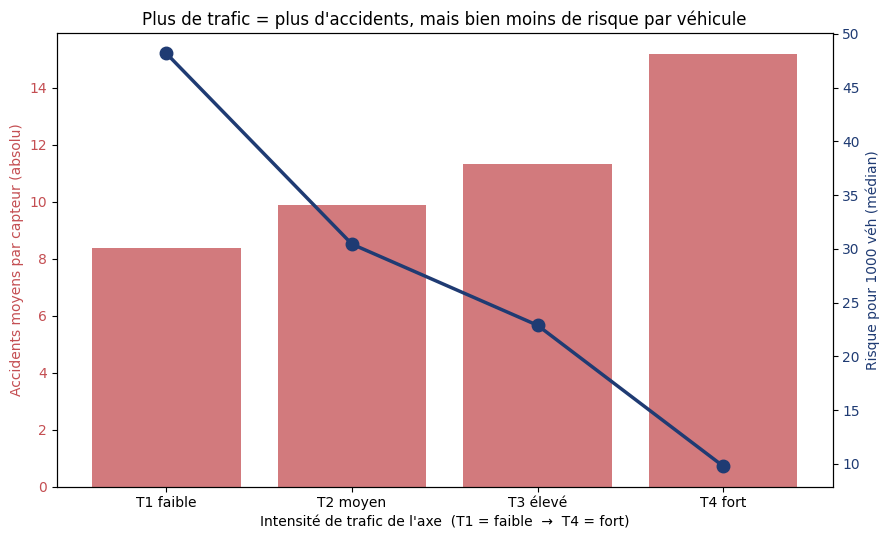

In [56]:
import matplotlib.pyplot as plt

x = synth.index.astype(str)

fig, ax1 = plt.subplots(figsize=(9, 5.5))

# Barres : accidents en ABSOLU (axe de gauche)
ax1.bar(x, synth["acc_moyen"], color="#C44E52", alpha=0.75)
ax1.set_ylabel("Accidents moyens par capteur (absolu)", color="#C44E52")
ax1.tick_params(axis="y", labelcolor="#C44E52")

# Courbe : risque PAR VÉHICULE (axe de droite)
ax2 = ax1.twinx()
ax2.plot(x, synth["risque_median"], "o-", color="#1f3b73", linewidth=2.5, markersize=9)
ax2.set_ylabel("Risque pour 1000 véh (médian)", color="#1f3b73")
ax2.tick_params(axis="y", labelcolor="#1f3b73")

ax1.set_xlabel("Intensité de trafic de l'axe  (T1 = faible  →  T4 = fort)")
plt.title("Plus de trafic = plus d'accidents, mais bien moins de risque par véhicule")
plt.tight_layout()
plt.show()

### Dataviz centrale
- Double axe : accidents absolus (barres) vs risque par véhicule (courbe).
- Tendances opposées = cœur du projet : le volume monte, le risque/véhicule chute.
- Réserve : le "croisement" visuel dépend des échelles ; le message repose sur les tendances (prouvées), pas sur l'intersection.

In [57]:
import folium

# Centre de Paris
m = folium.Map(location=[48.8566, 2.3522], zoom_start=12, tiles="CartoDB positron")

# On colore chaque capteur selon son risque : vert = sûr, rouge = sur-risque
def couleur(r):
    if r < 15:   return "green"
    if r < 40:   return "orange"
    return "red"

for _, row in cap.iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=4,
        color=couleur(row["risque_1000veh"]),
        fill=True, fill_opacity=0.7,
        popup=f"{row['libelle']} — risque: {row['risque_1000veh']:.0f}/1000véh"
    ).add_to(m)

m  # affiche la carte interactive dans Colab

### Carte du risque par capteur (Folium)
- Périphérique majoritairement vert → confirme : axe le plus circulé = plus sûr par véhicule (cohérent T4).
- Intérieur = patchwork vert/orange/rouge, sur-risque dispersé (pas un seul quartier).
- Carte plus bruitée que le graphe en tiers (qui moyenne) → la tendance est réelle/prouvée, mais le risque
  varie fortement d'un axe à l'autre. Illustration, pas preuve (la preuve = tests stat).

In [58]:
# Table 1 : les capteurs (1 ligne = 1 capteur avec son débit, son risque, sa position)
cap_export = cap[["iu_ac", "libelle", "tier", "q_moy", "n_acc", "risque_1000veh", "lat", "lon"]]
cap_export.to_csv("capteurs_risque.csv", index=False, encoding="utf-8-sig")

# Table 2 : les accidents rattachés (1 ligne = 1 accident, pour les filtres/cartes détaillées)
acc_export = near[["id_accident", "date", "gravite", "victime_type", "categorie",
                   "latitude", "longitude", "cap_iu", "cap_dist_m"]]
acc_export.to_csv("accidents_geocodes.csv", index=False, encoding="utf-8-sig")

print("Exporté :", cap_export.shape, "capteurs &", acc_export.shape, "accidents")

Exporté : (1907, 8) capteurs & (24840, 9) accidents


## Conclusion

### Question de départ
Le danger d'un axe routier parisien est-il proportionnel à son trafic ? Plus précisément :
à exposition égale (nombre de véhicules), le risque d'accident dépend-il du niveau de trafic de l'axe ?

### Résultat principal
Le risque d'accident **par véhicule n'est pas constant — il décroît fortement quand le trafic augmente.**

| Tier de trafic | Débit moyen (véh/h) | Accidents (absolu) | Risque /1000 véh |
|---|---|---|---|
| T1 (faible) | 139 | 8,4 | 48,2 |
| T2 | 244 | 9,9 | 30,4 |
| T3 | 398 | 11,3 | 22,9 |
| T4 (fort) | 1 555 | 15,2 | 9,8 |

- **En absolu**, les accidents augmentent avec le trafic (8,4 → 15,2 par capteur) : attendu.
- **Par véhicule**, le risque s'effondre (48 → 10, soit ~5×) : les axes les plus circulés
  (périphérique) sont les plus sûrs rapportés au volume.
- Confirmé statistiquement : Kruskal-Wallis (p ≈ 8e-78) et corrélation de Spearman négative
  (rho = −0,46, p ≈ 3e-100).

### Interprétation
« Plus de trafic » n'est pas une cause de sécurité. Les axes à fort débit (périphérique, voies
rapides) sont surtout **séparés des piétons, sans intersections, à vitesse régulée** — c'est cette
**configuration** qui réduit le risque par véhicule, pas le volume en lui-même. Le trafic est un
**marqueur** de la hiérarchie des voies, pas un facteur causal.

### Ce qu'on peut affirmer
- À Paris, sur le réseau instrumenté, le risque par véhicule décroît significativement avec le trafic de l'axe.
- L'intuition « beaucoup d'accidents = axe dangereux » confond volume et risque : elle est trompeuse.
- 82 % des victimes ne sont pas en voiture (2-roues, piétons, vélos) ; les piétons ont la plus forte
  part d'accidents graves (10 %).

### Ce qu'on NE peut PAS affirmer
- Aucune **causalité** : on observe une corrélation (modérée, rho = −0,46), pas un mécanisme.
- Rien sur les **petites rues** : 26 % des accidents (loin de tout capteur) ont été écartés ;
  l'étude porte sur le réseau structurant, pas sur toutes les voies de Paris.
- Rien sur l'**heure** des accidents (donnée absente) ni sur une évolution temporelle fine.

### Limites & biais déclarés
- **Décalage temporel** : trafic 2025-2026 utilisé comme proxy d'exposition pour des accidents
  2019-2024 (hypothèse : la hiérarchie des voies est stable dans le temps).
- **Biais de couverture** : seuls les ~1 900 axes instrumentés sont analysés.
- **Biais de rattachement** : seuil de 150 m → les accidents des petites rues sont exclus.
- **Qualité capteurs** : 49 capteurs à débit implausible (< 50 véh/h) retirés ; 2 défaillants (débit nul).
- **Instabilité de l'export** : le nombre d'accidents varie légèrement entre deux téléchargements.

### Phrase de synthèse
> *Rapporté au nombre de véhicules, l'axe le plus circulé de Paris — le périphérique — est parmi
> les plus sûrs. Le risque routier est piloté par la configuration de la voie, pas par le volume de trafic.*